# Exercise 1 - Multi-Layer Perceptron classifier (CIFAR-10)

**PUSL3123 AI and Machine Learning - Assessment 1**

**Aim:** build, train and evaluate a Multi-Layer Perceptron (MLP) with three trainable layers on CIFAR-10 using PyTorch.

**Contents**
1. Setup and configuration
2. Data preparation (standard partitions, validation split, class distribution)
3. Helper functions (training, evaluation, plotting)
4. Model: three-layer MLP
5. Training
6. Training and validation curves
7. Final evaluation (train / validation / test)
8. Save results

**How to run:** `pip install -r requirements.txt`, then *Run All*. Set the environment variable `QUICK_RUN=1` for a 2-epoch smoke test. The dataset downloads automatically into `data/`.

## 1. Setup and configuration

All four notebooks share the same configuration (seed, validation size, batch size, learning rate, epochs) so that results are directly comparable.

In [1]:
import os, json, time, random

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
import torchvision
import torchvision.transforms as T

# ---------------------------------------------------------------------------
# Configuration -- identical in all four notebooks so that results are comparable
# ---------------------------------------------------------------------------
SEED          = 42        # seed for the train/validation split, weight initialisation and shuffling
VAL_SIZE      = 5_000     # validation images held out from the 50,000 training images
BATCH_SIZE    = 128
LEARNING_RATE = 1e-3
EPOCHS        = 2 if os.environ.get("QUICK_RUN") else 30   # set QUICK_RUN=1 for a 2-epoch smoke test
DATA_DIR      = "data"
RESULTS_DIR   = "results"
FIG_DIR       = os.path.join(RESULTS_DIR, "figures")
DEVICE        = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_WORKERS   = 0 if os.name == "nt" else 2   # 0 avoids multiprocessing problems on Windows
CLASSES = ("aeroplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck")

os.makedirs(FIG_DIR, exist_ok=True)

def set_seed(seed=SEED):
    """Make runs reproducible."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__)
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU only")
print(f"Epochs: {EPOCHS} | batch size: {BATCH_SIZE} | learning rate: {LEARNING_RATE} | seed: {SEED}")

PyTorch 2.5.1+cu121 | torchvision 0.20.1+cu121
Device: cuda | NVIDIA GeForce RTX 4050 Laptop GPU
Epochs: 30 | batch size: 128 | learning rate: 0.001 | seed: 42


## 2. Data preparation

* CIFAR-10 is loaded with `torchvision.datasets.CIFAR10` using the **standard partitions**: 50,000 training images and 10,000 test images.
* The test partition is kept completely separate: it is **not** used for training, hyper-parameter tuning or model selection.
* A **validation set of 5,000 images is held out from the 50,000 training images** with a fixed random seed, leaving 45,000 images for training. The same split is used in every experiment.
* Images are converted to tensors and normalised per channel with the CIFAR-10 mean and standard deviation. No data augmentation is used in this exercise.

In [2]:
# Per-channel mean / std of the CIFAR-10 training images
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
eval_transform = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])

def build_data(train_transform=eval_transform):
    """Standard CIFAR-10 partitions (50,000 train / 10,000 test). A fixed validation set is held out
    from the training images; the test set is never used for training or model selection."""
    train_aug   = torchvision.datasets.CIFAR10(DATA_DIR, train=True,  download=True, transform=train_transform)
    train_clean = torchvision.datasets.CIFAR10(DATA_DIR, train=True,  download=True, transform=eval_transform)
    test_set    = torchvision.datasets.CIFAR10(DATA_DIR, train=False, download=True, transform=eval_transform)

    perm = torch.randperm(len(train_aug), generator=torch.Generator().manual_seed(SEED)).tolist()
    val_idx, train_idx = perm[:VAL_SIZE], perm[VAL_SIZE:]

    pin = DEVICE.type == "cuda"
    def loader(ds, shuffle):
        gen = torch.Generator().manual_seed(SEED) if shuffle else None
        return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle,
                          num_workers=NUM_WORKERS, pin_memory=pin, generator=gen)

    return {
        "train":       loader(Subset(train_aug,   train_idx), shuffle=True),   # used for training
        "train_clean": loader(Subset(train_clean, train_idx), shuffle=False),  # same images, no augmentation
        "val":         loader(Subset(train_clean, val_idx),   shuffle=False),  # validation (model selection)
        "test":        loader(test_set,                       shuffle=False),  # final reporting only
    }

loaders = build_data()
print("Images per partition:", {k: len(v.dataset) for k, v in loaders.items()})

Files already downloaded and verified


Files already downloaded and verified


Files already downloaded and verified


Images per partition: {'train': 45000, 'train_clean': 45000, 'val': 5000, 'test': 10000}


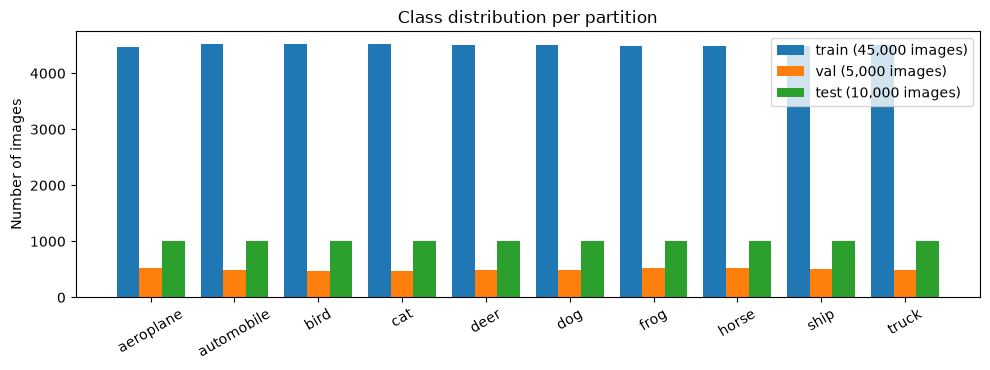

Files already downloaded and verified


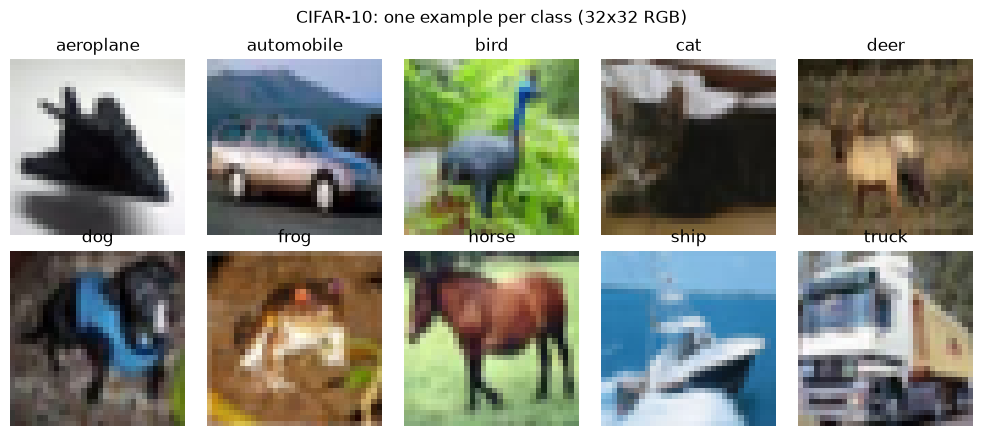

In [3]:
def class_counts(ds):
    """Number of images per class for a Subset or a full dataset."""
    if isinstance(ds, Subset):
        return np.bincount(np.array(ds.dataset.targets)[ds.indices], minlength=len(CLASSES))
    return np.bincount(np.array(ds.targets), minlength=len(CLASSES))

counts = {name: class_counts(loaders[name].dataset) for name in ("train", "val", "test")}

x, w = np.arange(len(CLASSES)), 0.27
plt.figure(figsize=(10, 3.8))
for i, (name, c) in enumerate(counts.items()):
    plt.bar(x + (i - 1) * w, c, w, label=f"{name} ({c.sum():,} images)")
plt.xticks(x, CLASSES, rotation=30)
plt.ylabel("Number of images")
plt.title("Class distribution per partition")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "class_distribution.png"), dpi=200)
plt.show()

# One example image per class
raw = torchvision.datasets.CIFAR10(DATA_DIR, train=True, download=True)
raw_targets = np.array(raw.targets)
fig, axes = plt.subplots(2, 5, figsize=(10, 4.4))
for c, ax in enumerate(axes.ravel()):
    ax.imshow(raw[int(np.where(raw_targets == c)[0][0])][0])
    ax.set_title(CLASSES[c])
    ax.axis("off")
fig.suptitle("CIFAR-10: one example per class (32x32 RGB)")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "cifar10_samples.png"), dpi=200)
plt.show()

## 3. Helper functions

* `fit` trains with **Adam** and **cross-entropy loss**, records loss and accuracy per epoch, and restores the weights of the epoch with the best **validation** accuracy.
* `evaluate` / `final_evaluation` compute loss and accuracy; the test set is only used in `final_evaluation`, after training has finished.
* Plotting and saving utilities produce the figures and JSON results used in the report.

In [4]:
def count_parameters(model):
    """Number of trainable parameters."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

@torch.no_grad()
def evaluate(model, loader):
    """Mean cross-entropy loss and accuracy of `model` on `loader` (eval mode: no dropout)."""
    criterion = nn.CrossEntropyLoss()
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        out = model(x)
        total_loss += criterion(out, y).item() * y.size(0)
        correct += (out.argmax(1) == y).sum().item()
        n += y.size(0)
    return total_loss / n, correct / n

def fit(model, train_loader, val_loader, epochs=EPOCHS, lr=LEARNING_RATE, weight_decay=0.0):
    """Train with Adam + cross-entropy. After every epoch the model is scored on the validation set; the
    weights of the epoch with the highest validation accuracy are restored at the end (model selection
    uses validation data only -- never the test set)."""
    criterion = nn.CrossEntropyLoss()
    optimiser = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_acc, best_epoch, best_state = -1.0, 0, None
    start = time.time()

    for epoch in range(1, epochs + 1):
        model.train()
        run_loss, run_correct, seen = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimiser.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimiser.step()
            run_loss += loss.item() * y.size(0)
            run_correct += (out.argmax(1) == y).sum().item()
            seen += y.size(0)

        val_loss, val_acc = evaluate(model, val_loader)
        history["train_loss"].append(run_loss / seen)
        history["train_acc"].append(run_correct / seen)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc, best_epoch = val_acc, epoch
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}

        print(f"Epoch {epoch:02d}/{epochs} | train loss {history['train_loss'][-1]:.4f} "
              f"acc {history['train_acc'][-1]:.4f} | val loss {val_loss:.4f} acc {val_acc:.4f}")

    model.load_state_dict(best_state)
    return history, best_epoch, time.time() - start

def final_evaluation(model, loaders):
    """Loss / accuracy on the clean training images, the validation set and the test set."""
    result = {}
    for key, loader_name in (("train", "train_clean"), ("val", "val"), ("test", "test")):
        loss, acc = evaluate(model, loaders[loader_name])
        result[f"{key}_loss"], result[f"{key}_acc"] = loss, acc
    return result

def print_final(final):
    print(f"{'Partition':<12}{'Loss':>8}{'Accuracy':>11}")
    for part in ("train", "val", "test"):
        print(f"{part:<12}{final[part + '_loss']:>8.4f}{final[part + '_acc'] * 100:>10.2f}%")
    gap = (final["train_acc"] - final["test_acc"]) * 100
    print(f"Generalisation gap (train - test accuracy): {gap:.2f} percentage points")

def plot_history(history, best_epoch, title, filename):
    """Training vs validation loss (left) and accuracy (right)."""
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(epochs, history["train_loss"], label="Training loss")
    axes[0].plot(epochs, history["val_loss"], label="Validation loss")
    axes[0].set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Loss")
    axes[1].plot(epochs, history["train_acc"], label="Training accuracy")
    axes[1].plot(epochs, history["val_acc"], label="Validation accuracy")
    axes[1].set(xlabel="Epoch", ylabel="Accuracy", title="Accuracy")
    for ax in axes:
        ax.axvline(best_epoch, ls="--", c="grey", label=f"Selected epoch ({best_epoch})")
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, filename), dpi=200)
    plt.show()

@torch.no_grad()
def predict(model, loader):
    model.eval()
    preds, labels = [], []
    for x, y in loader:
        preds.append(model(x.to(DEVICE)).argmax(1).cpu())
        labels.append(y)
    return torch.cat(preds).numpy(), torch.cat(labels).numpy()

def plot_confusion_matrix(model, loader, title, filename):
    """Confusion matrix (rows = true class, columns = predicted class). Returns the count matrix."""
    preds, labels = predict(model, loader)
    cm = np.zeros((len(CLASSES), len(CLASSES)), dtype=int)
    np.add.at(cm, (labels, preds), 1)
    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    im = ax.imshow(cm, cmap="Blues")
    ax.set(xticks=range(len(CLASSES)), yticks=range(len(CLASSES)), xlabel="Predicted class",
           ylabel="True class", title=title)
    ax.set_xticklabels(CLASSES, rotation=45, ha="right")
    ax.set_yticklabels(CLASSES)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    fig.colorbar(im, ax=ax, fraction=0.046)
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, filename), dpi=200)
    plt.show()
    return cm

def save_results(name, payload):
    """Write results to results/<name>.json (used for the tables and graphs in the report)."""
    path = os.path.join(RESULTS_DIR, f"{name}.json")
    with open(path, "w") as f:
        json.dump(payload, f, indent=2)
    print("Saved", path)

## 4. Model: three-layer MLP

The MLP flattens each 3x32x32 image into 3,072 values and passes it through three fully connected (trainable) layers:

| Layer | Shape | Activation |
|---|---|---|
| Linear 1 | 3072 -> 1024 | ReLU |
| Linear 2 | 1024 -> 512 | ReLU |
| Linear 3 | 512 -> 10 | none (logits) |

**Design choices**
* **ReLU** activations: cheap, avoid vanishing gradients in the hidden layers.
* **Cross-entropy loss**: the standard loss for multi-class classification (it applies softmax internally, so the last layer outputs raw logits).
* **Adam** (learning rate 1e-3): adaptive optimiser that works well with little tuning.
* No dropout or augmentation here, so this MLP is a plain baseline.

In [5]:
class MLP(nn.Module):
    """Multi-Layer Perceptron with three trainable (fully connected) layers: 3072 -> 1024 -> 512 -> 10."""
    def __init__(self, hidden1=1024, hidden2=512, num_classes=len(CLASSES)):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),                       # 3 x 32 x 32 image -> vector of 3072 values
            nn.Linear(3 * 32 * 32, hidden1),    # trainable layer 1
            nn.ReLU(),
            nn.Linear(hidden1, hidden2),        # trainable layer 2
            nn.ReLU(),
            nn.Linear(hidden2, num_classes),    # trainable layer 3 (class scores / logits)
        )

    def forward(self, x):
        return self.net(x)

set_seed(SEED)
model = MLP().to(DEVICE)
print(model)
print()
for name, p in model.named_parameters():
    print(f"{name:14s} {str(tuple(p.shape)):16s} {p.numel():>10,}")
n_params = count_parameters(model)
print(f"\nTotal trainable parameters: {n_params:,}")

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=1024, bias=True)
    (2): ReLU()
    (3): Linear(in_features=1024, out_features=512, bias=True)
    (4): ReLU()
    (5): Linear(in_features=512, out_features=10, bias=True)
  )
)

net.1.weight   (1024, 3072)      3,145,728
net.1.bias     (1024,)               1,024
net.3.weight   (512, 1024)         524,288
net.3.bias     (512,)                  512
net.5.weight   (10, 512)             5,120
net.5.bias     (10,)                    10

Total trainable parameters: 3,676,682


## 5. Training

In [6]:
history, best_epoch, train_seconds = fit(model, loaders["train"], loaders["val"])
print(f"\nSelected epoch {best_epoch} (highest validation accuracy) | training time {train_seconds:.0f} s")

Epoch 01/30 | train loss 1.6716 acc 0.4074 | val loss 1.5286 acc 0.4580


Epoch 02/30 | train loss 1.4551 acc 0.4862 | val loss 1.4348 acc 0.4968


Epoch 03/30 | train loss 1.3520 acc 0.5197 | val loss 1.4433 acc 0.4978


Epoch 04/30 | train loss 1.2592 acc 0.5530 | val loss 1.4296 acc 0.5086


Epoch 05/30 | train loss 1.1808 acc 0.5813 | val loss 1.5027 acc 0.4972


Epoch 06/30 | train loss 1.0938 acc 0.6102 | val loss 1.4296 acc 0.5256


... (20 outputs left out)

Epoch 27/30 | train loss 0.2987 acc 0.8958 | val loss 3.0630 acc 0.5298


Epoch 28/30 | train loss 0.3003 acc 0.8948 | val loss 3.0573 acc 0.5340


Epoch 29/30 | train loss 0.2837 acc 0.9023 | val loss 3.0496 acc 0.5326


Epoch 30/30 | train loss 0.2684 acc 0.9064 | val loss 3.1785 acc 0.5346

Selected epoch 23 (highest validation accuracy) | training time 471 s


## 6. Training and validation curves

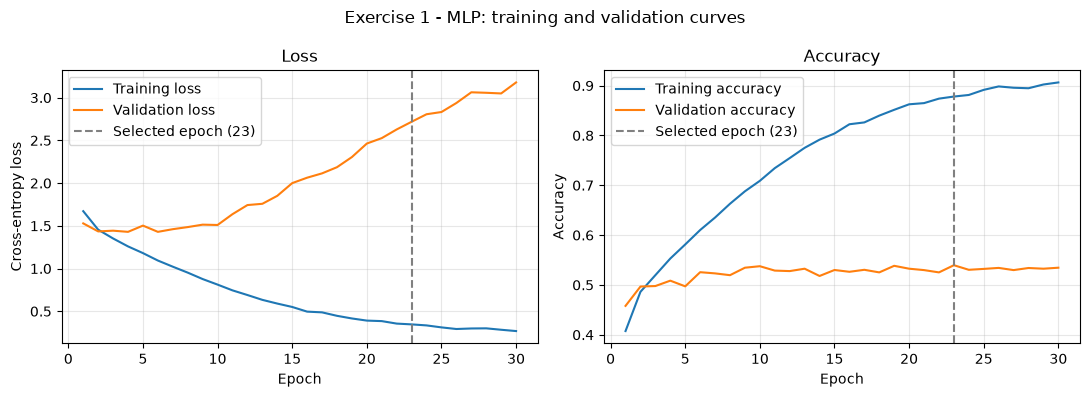

In [7]:
plot_history(history, best_epoch, "Exercise 1 - MLP: training and validation curves", "ex1_mlp_curves.png")

## 7. Final evaluation

The selected model is evaluated once on the clean training images, the validation set and the test set. The confusion matrix shows which classes the MLP mixes up.

Partition       Loss   Accuracy
train         0.3209     88.68%
val           2.7180     53.96%
test          2.6700     53.11%
Generalisation gap (train - test accuracy): 35.57 percentage points


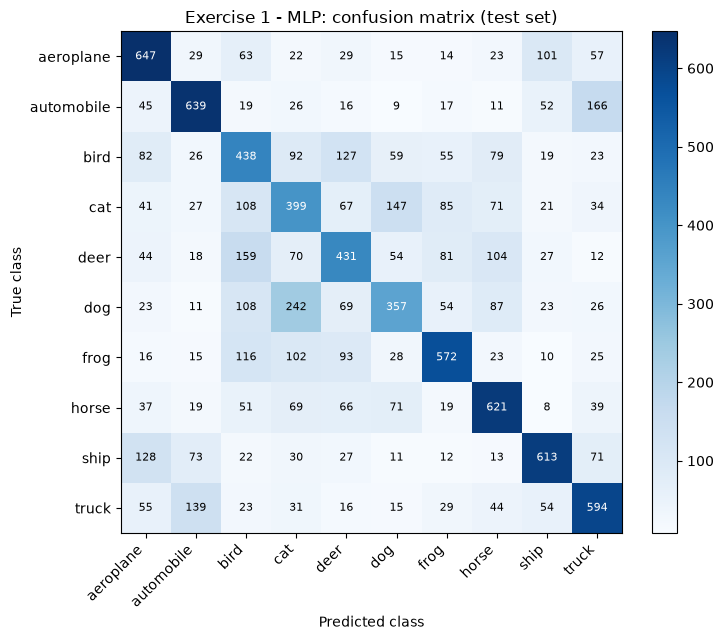


Per-class test accuracy:
  aeroplane   64.70%
  automobile  63.90%
  horse       62.10%
  ship        61.30%
  truck       59.40%
  frog        57.20%
  bird        43.80%
  deer        43.10%
  cat         39.90%
  dog         35.70%


In [8]:
final = final_evaluation(model, loaders)
print_final(final)

cm = plot_confusion_matrix(model, loaders["test"], "Exercise 1 - MLP: confusion matrix (test set)", "ex1_mlp_confusion.png")
per_class = cm.diagonal() / cm.sum(axis=1)
print("\nPer-class test accuracy:")
for name, acc in sorted(zip(CLASSES, per_class), key=lambda t: -t[1]):
    print(f"  {name:<11}{acc * 100:6.2f}%")

## 8. Save results

The numbers are stored in `results/ex1_mlp.json` so that the report and the later comparison with the CNN (Exercise 2) use exactly the values produced here.

In [9]:
save_results("ex1_mlp", {
    "experiment": "Exercise 1 - MLP",
    "model": "MLP 3072-1024-512-10 (ReLU)",
    "trainable_parameters": n_params,
    "best_epoch": best_epoch,
    "train_seconds": round(train_seconds, 1),
    "device": str(DEVICE),
    "config": {"seed": SEED, "val_size": VAL_SIZE, "batch_size": BATCH_SIZE, "epochs": EPOCHS,
               "learning_rate": LEARNING_RATE, "optimiser": "Adam", "loss": "CrossEntropyLoss"},
    "final": final,
    "history": history,
    "confusion_matrix_test": cm.tolist(),
})

Saved results\ex1_mlp.json
